In [1]:
from matplotlib import pyplot as plt

In [2]:
import numpy as np

/tmp/nix-shell-3131-0/ipykernel_3360/848097236.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(new_labels)
/tmp/nix-shell-3131-0/ipykernel_3360/848097236.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels)


Text(0.5, 1.0, 'Cost Efficiency: Local FT vs Cloud PE')

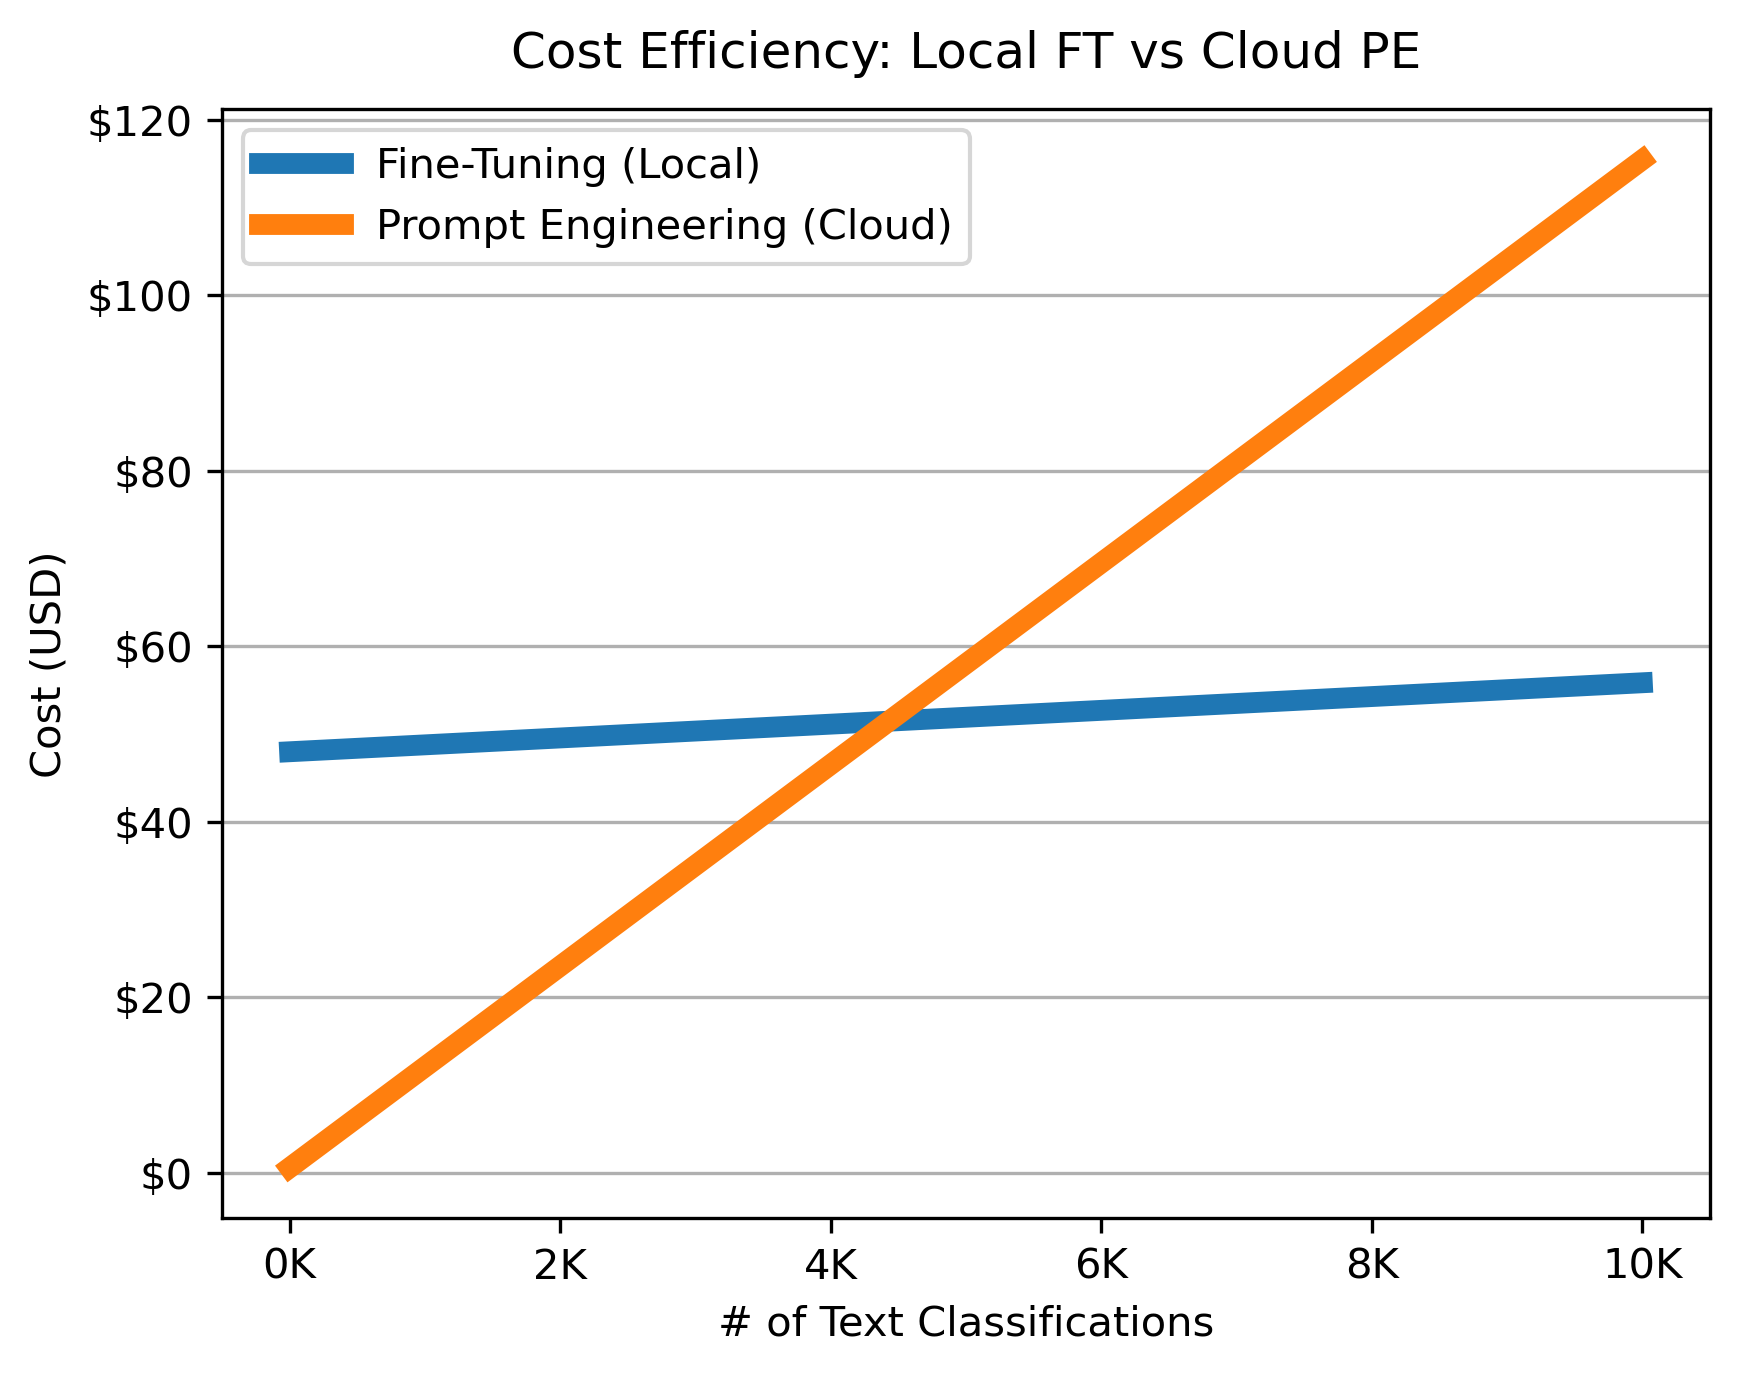

In [247]:
FT_TRAIN_COST = 48
PE_TRAIN_COST = 0.6

FT_SAMPLE_COST = 786 / 1000000
PE_SAMPLE_COST = 11485 / 1000000

x = [0, 10000]
FT = [FT_TRAIN_COST, FT_TRAIN_COST + FT_SAMPLE_COST * max(x)]
PE = [PE_TRAIN_COST, PE_TRAIN_COST + PE_SAMPLE_COST * max(x)]

plt.rcParams['figure.dpi'] = 300

plt.plot(x, FT, x, PE, linewidth=5)
plt.xlabel("# of Text Classifications")
plt.ylabel("Cost (USD)")#, rotation="horizontal", labelpad=40)
#plt.ylim([0, max(x)])

ax = plt.gca()
ticks = ax.get_yticks()
# formatted the values into strings beginning with dollar sign
new_labels = [f'${int(amt)}' for amt in ticks]
# Set the new labels
ax.set_yticklabels(new_labels)

ticks = ax.get_xticks()
new_labels = [f'{int(amt) // 1000}K' for amt in ticks]
ax.set_xticklabels(new_labels)

plt.legend(["Fine-Tuning (Local)", "Prompt Engineering (Cloud)"])

plt.grid(axis='y')

plt.title("Cost Efficiency: Local FT vs Cloud PE", pad=10)

/tmp/nix-shell-3131-0/ipykernel_3360/3791159036.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(new_labels)


Text(0.5, 1.0, 'Token Efficiency: Local FT vs Cloud PE')

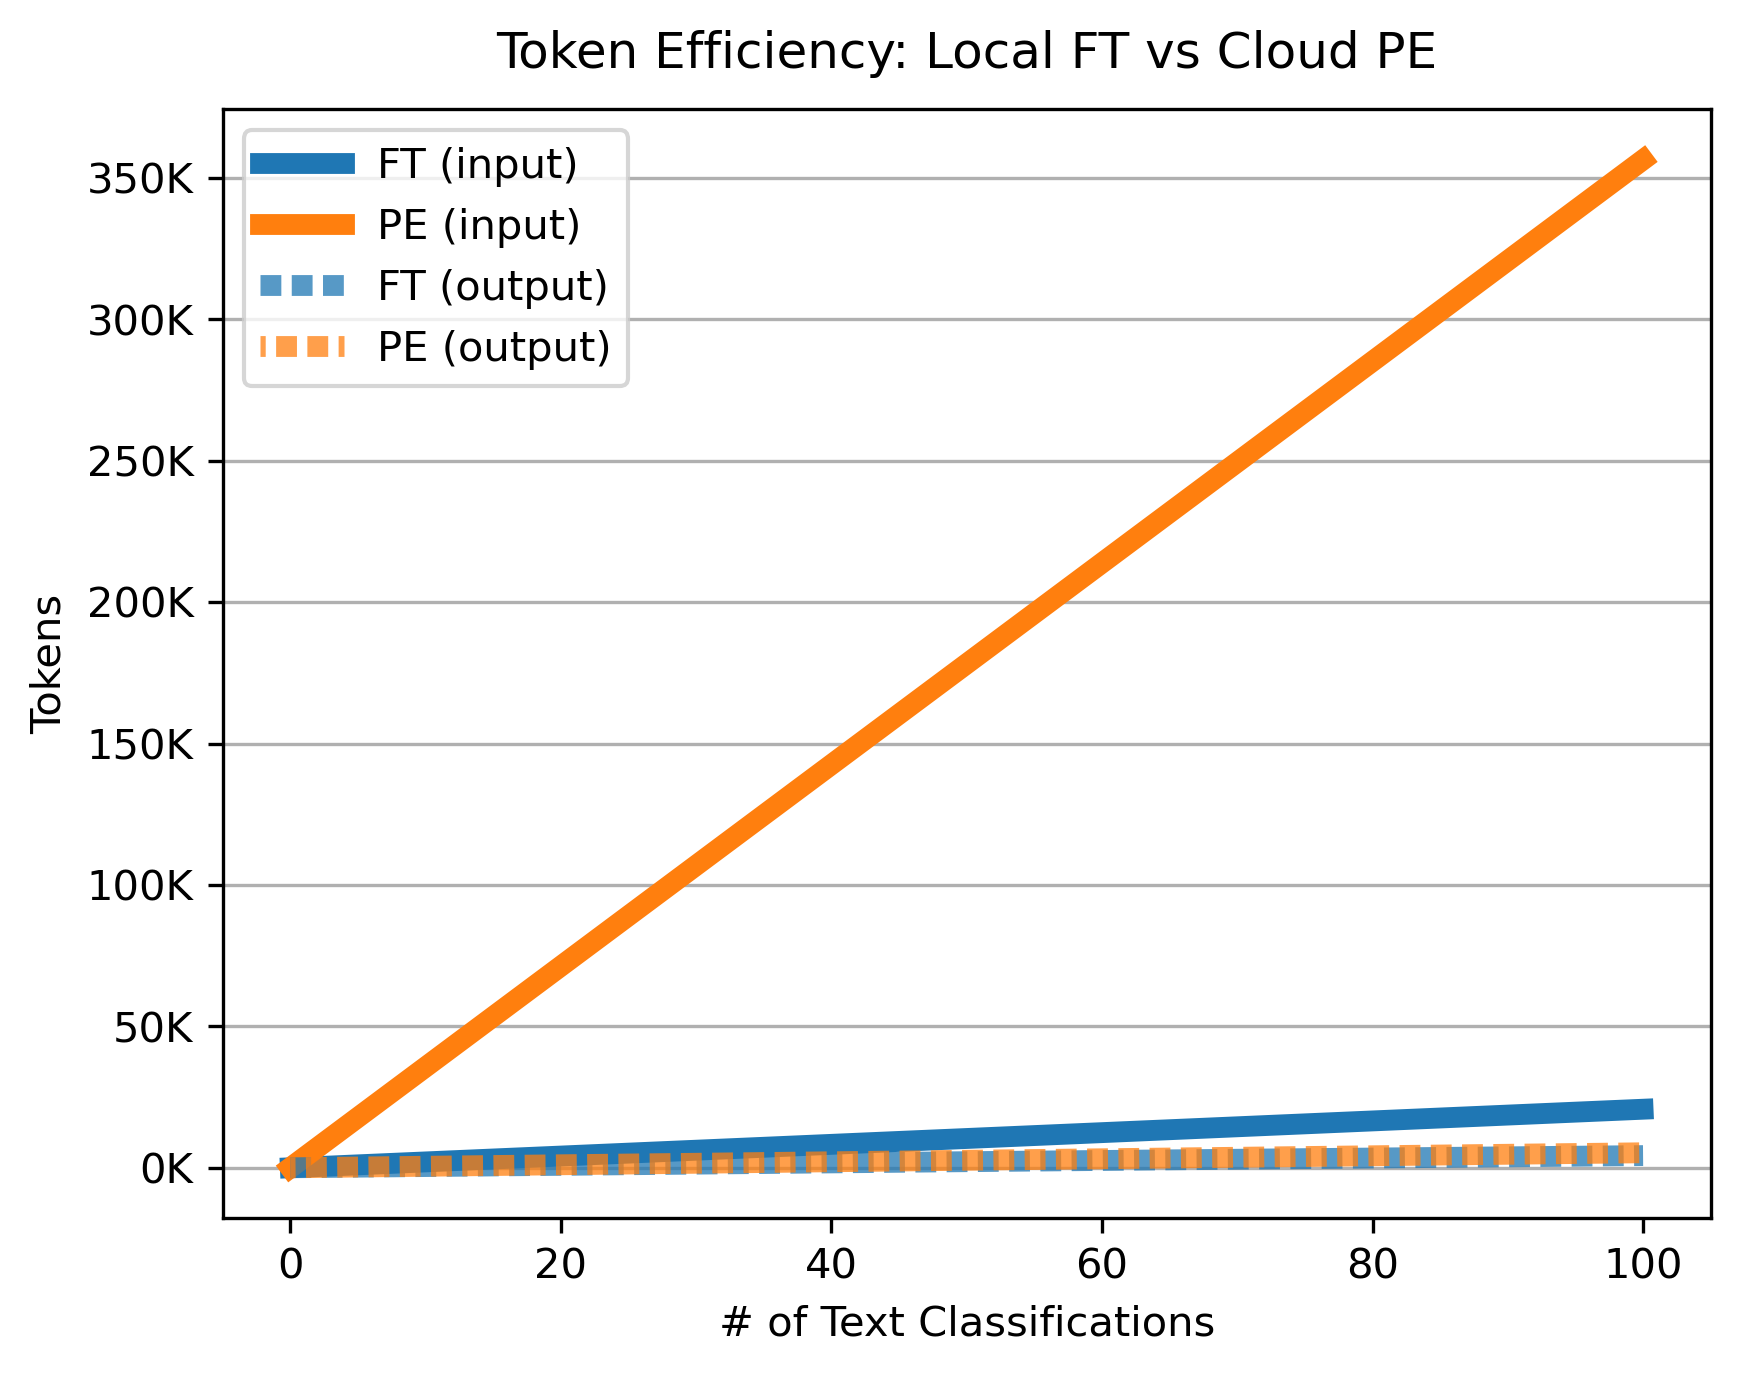

In [246]:
x = [0, 100]

FT_IN_TOKEN_COST = 207
FT_OUT_TOKEN_COST = 43
PE_IN_TOKEN_COST = 3564
PE_OUT_TOKEN_COST = 53

FT_IN_TOKENS = [0, FT_IN_TOKEN_COST * max(x)]
PE_IN_TOKENS = [0, PE_IN_TOKEN_COST * max(x)]
FT_OUT_TOKENS = [0, FT_OUT_TOKEN_COST * max(x)]
PE_OUT_TOKENS = [0, PE_OUT_TOKEN_COST * max(x)]

plt.plot(x, FT_IN_TOKENS, color = 'C0', linewidth = 5, label = "FT (input)")
plt.plot(x, PE_IN_TOKENS, color = 'C1', linewidth = 5, label = "PE (input)")
plt.plot(x, FT_OUT_TOKENS, color = 'C0', linewidth = 5, alpha = 0.75, linestyle=(0,(1,0.5)), label = "FT (output)")
plt.plot(x, PE_OUT_TOKENS, color = 'C1', linewidth = 5, alpha = 0.75, linestyle=(0.75,(1,0.5)), label = "PE (output)")

plt.ylabel("Tokens")#, rotation=0, labelpad=40)
plt.xlabel("# of Text Classifications")


ax = plt.gca()
ticks = ax.get_yticks()
new_labels = [f'{int(amt) // 1000}K' for amt in ticks]
ax.set_yticklabels(new_labels)

plt.legend()

plt.grid(axis='y')

plt.title("Token Efficiency: Local FT vs Cloud PE", pad=10)

/tmp/nix-shell-3131-0/ipykernel_3360/3097391462.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_labels)
/tmp/nix-shell-3131-0/ipykernel_3360/3097391462.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(new_labels)


Text(0.5, 1.0, 'Inference Efficiency: Local FT vs Local & Cloud PE')

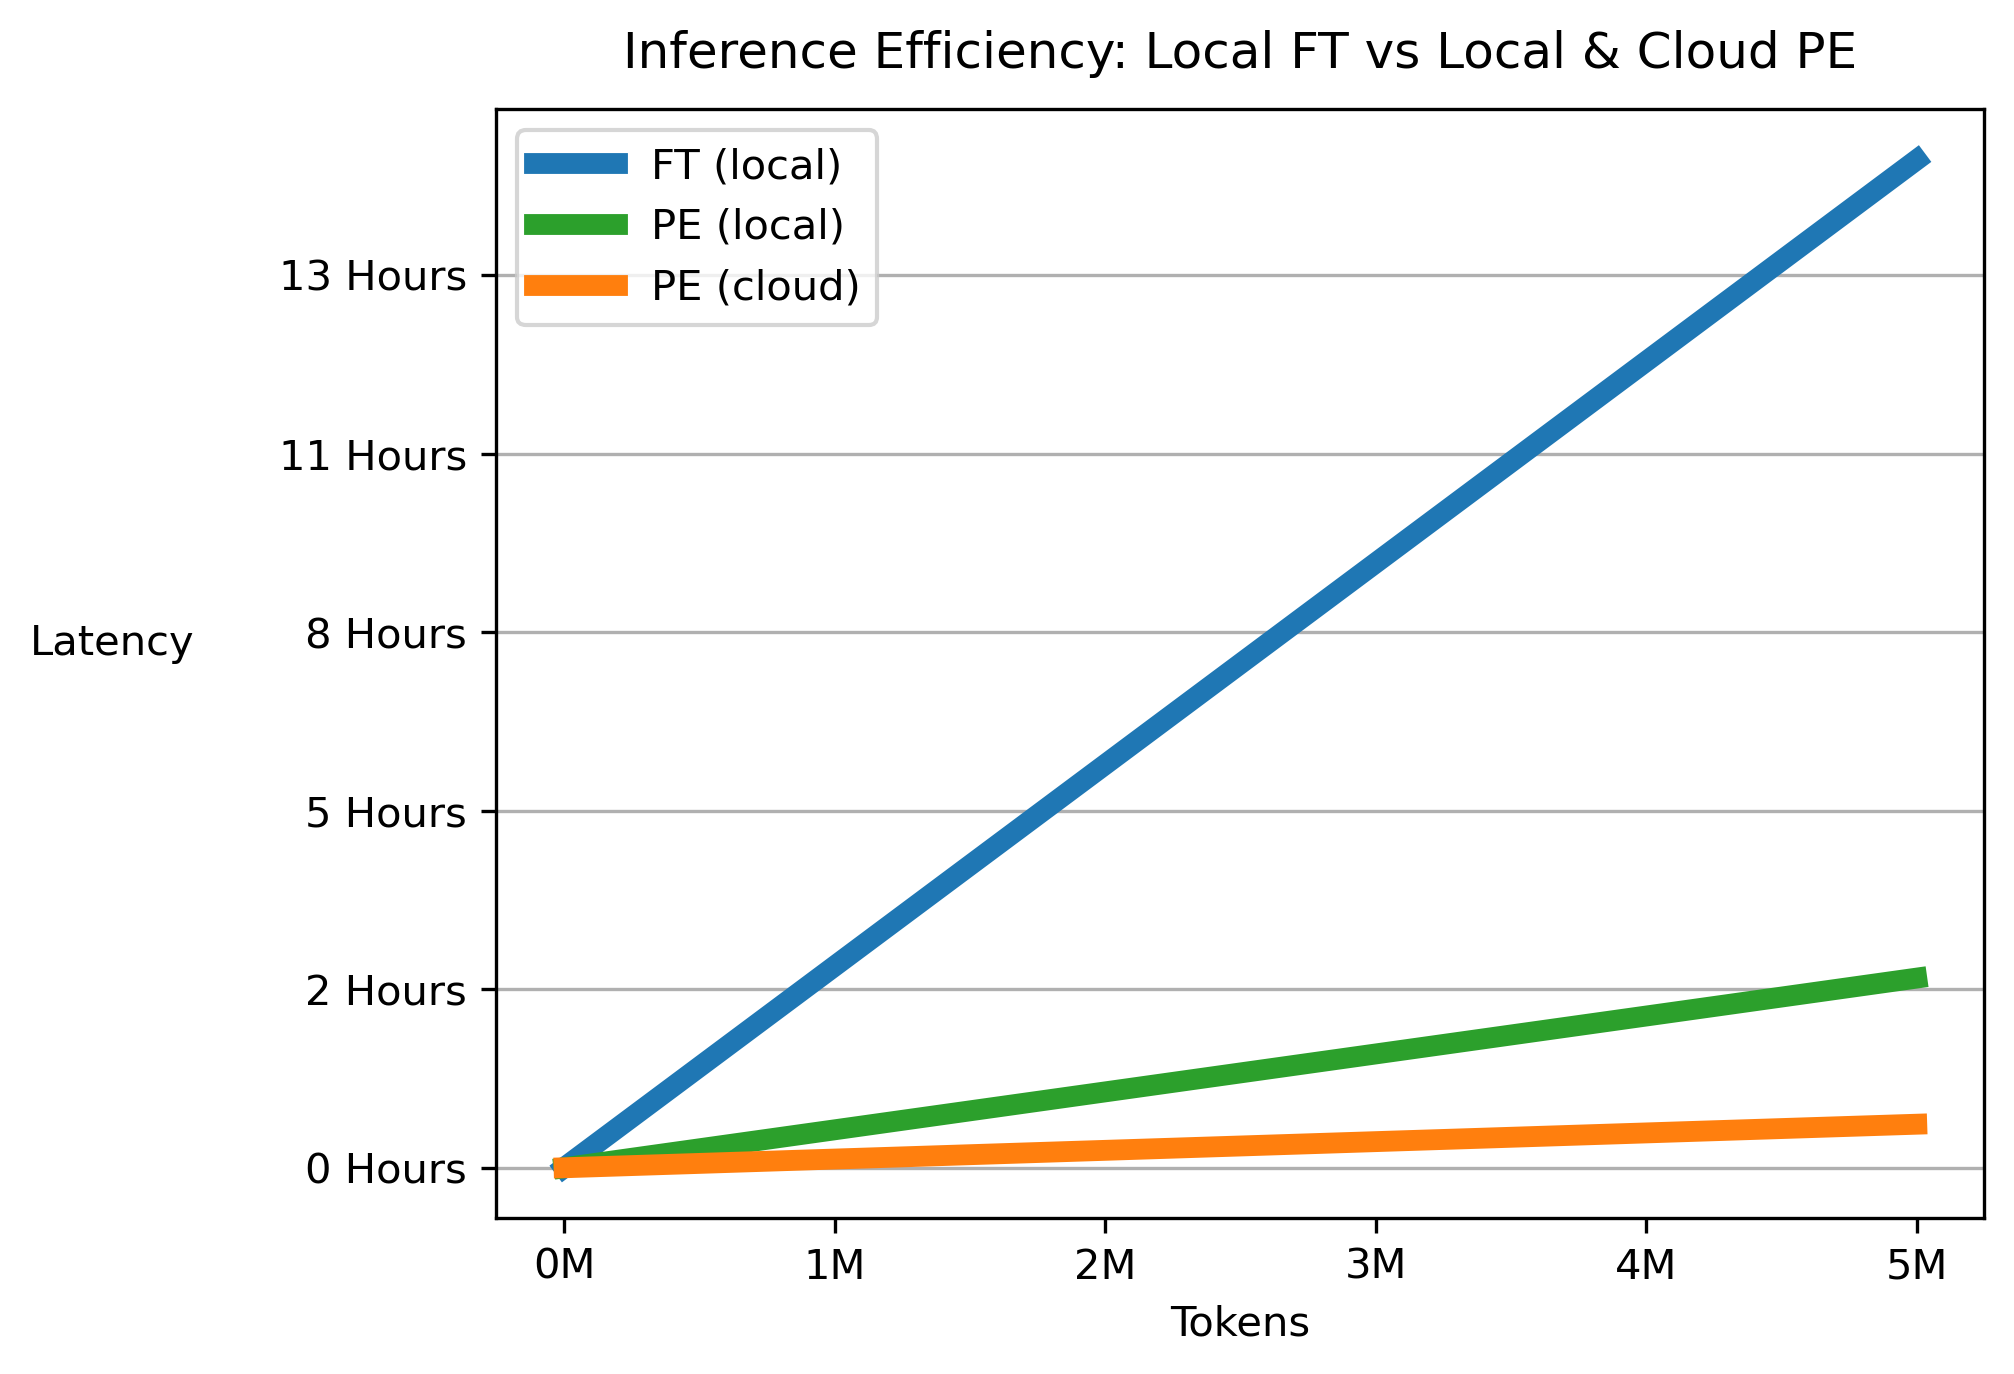

In [248]:
x = [0, 5000000]

FT_LATENCY_MTOK = 11293 / 1000000
PE_LOCAL_LATENCY_MTOK = 2125 / 1000000
PE_CLOUD_LATENCY_MTOK = 488 / 1000000

FT_LATENCY = [0, FT_LATENCY_MTOK * max(x)]
PE_LOCAL_LATENCY = [0, PE_LOCAL_LATENCY_MTOK * max(x)]
PE_CLOUD_LATENCY = [0, PE_CLOUD_LATENCY_MTOK * max(x)]

plt.plot(x, FT_LATENCY, color='C0', linewidth=5, label = "FT (local)")
plt.plot(x, PE_LOCAL_LATENCY, color='C2', linewidth=5, label = "PE (local)")
plt.plot(x, PE_CLOUD_LATENCY, color='C1', linewidth=5, label = "PE (cloud)")

plt.ylabel("Latency", rotation=0, labelpad=40)
plt.xlabel("Tokens")

ax = plt.gca()

ticks = ax.get_xticks()
new_labels = [f'{int(amt) // 1000000}M' for amt in ticks]
ax.set_xticklabels(new_labels)


ticks = ax.get_yticks()
new_labels = [f'{int(amt) // 3600} Hours' for amt in ticks]
ax.set_yticklabels(new_labels)

plt.legend()

plt.grid(axis='y')

plt.title("Inference Efficiency: Local FT vs Local & Cloud PE", pad=10)